# OECD Venture Capital Exploratory Analysis

This notebook explores venture capital investment across countries represented in the OECD Venture Capital Investments dataset from 2019 to 2025.

The analysis focuses on:

- temporal trends in reported VC investment;
- data coverage and panel consistency;
- geographic concentration;
- business development stage composition; and
- differences between the pre-GPT and post-GPT periods.

The OECD dataset is used primarily for cross-country and stage-level analysis. It should not be interpreted as a complete measure of global venture capital activity.

## 1. Load and Prepare the Data

The analysis uses the processed OECD dataset generated by the project's reproducible extraction and transformation pipeline.

Total investment observations are separated from stage-level observations to avoid double counting. The `_T` category represents reported total VC investment, while `SEED`, `START`, and `LATER` describe the stage composition where available.

In [18]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "oecd_vc_annual_2019_2025.csv"
)

df = pd.read_csv(DATA_PATH)

df.head()

,source_provider,source_dataset_id,country_code,country,stage_code,stage,year,vc_investment_usd_millions,observation_status_code,observation_status,unit_code,unit,unit_multiplier_code,unit_multiplier,currency_code,currency
0,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,LATER,Later stage venture,2019,342.02,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
1,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,SEED,Seed,2019,44.49,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
2,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,START,Start-up and other early stage,2019,100.80,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
3,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUS,Australia,_T,Total,2019,487.31,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar
4,OECD,OECD.SDD.TPS:DSD_VC@DF_VC_INV(1.0),AUT,Austria,LATER,Later stage venture,2019,33.96,A,Normal value,USD_EXC,"US dollars, exchange rate converted",6,Millions,USD,US dollar


In [19]:
total_vc = df[df["stage_code"] == "_T"].copy()

stage_vc = df[df["stage_code"].isin(["SEED", "START", "LATER"])].copy()

## 2. Dataset Structure

The processed dataset contains observations by country, year, and business development stage.

Initial descriptive statistics are used to confirm the analytical scope and examine differences in the distribution of investment across stage categories.

In [20]:
print(f"Rows: {len(df):,}")
print(f"Countries: {df['country_code'].nunique()}")
print(f"Years: {df['year'].min()}–{df['year'].max()}")

df.groupby("stage")["vc_investment_usd_millions"].agg(
    ["count", "sum", "mean", "median"]
)

Rows: 895
Countries: 37
Years: 2019–2025


,count,sum,mean,median
stage,,,,
Later stage venture,217,"768,081.25","3,539.54",96.30
Seed,217,"143,143.97",659.65,21.19
Start-up and other early stage,217,"518,512.98","2,389.46",105.89
Total,244,"1,468,047.60","6,016.59",247.21


## 3. Coverage and Balanced-Panel Robustness Check

Country-level reporting is not complete for every year in the dataset. A changing set of reporting countries could therefore distort aggregate trends.

To assess this risk, countries with total VC observations for all seven years from 2019 through 2025 are identified. Aggregate investment is then recalculated using only this balanced panel and compared with the full dataset.

In [21]:
country_year_counts = (
    total_vc
    .groupby(["country_code", "country"])["year"]
    .nunique()
    .sort_values(ascending=False)
)

country_year_counts

country_code  country        
HUN           Hungary            7
IRL           Ireland            7
SWE           Sweden             7
ROU           Romania            7
PRT           Portugal           7
POL           Poland             7
NZL           New Zealand        7
NOR           Norway             7
NLD           Netherlands        7
LVA           Latvia             7
LUX           Luxembourg         7
LTU           Lithuania          7
KOR           Korea              7
USA           United States      7
ITA           Italy              7
AUT           Austria            7
SVK           Slovak Republic    7
SVN           Slovenia           7
HRV           Croatia            7
GRC           Greece             7
GBR           United Kingdom     7
FRA           France             7
FIN           Finland            7
EST           Estonia            7
ESP           Spain              7
DNK           Denmark            7
DEU           Germany            7
CZE           Czechia    

In [22]:
balanced_countries = (
    country_year_counts[
        country_year_counts == 7
    ]
    .reset_index()["country_code"]
)

print(
    f"Countries with complete 2019–2025 coverage: "
    f"{len(balanced_countries)}"
)

print(
    f"Countries with incomplete coverage: "
    f"{total_vc['country_code'].nunique() - len(balanced_countries)}"
)

Countries with complete 2019–2025 coverage: 32
Countries with incomplete coverage: 5


In [23]:
balanced_total_vc = total_vc[
    total_vc["country_code"].isin(balanced_countries)
].copy()

balanced_annual_vc = (
    balanced_total_vc
    .groupby("year", as_index=False)
    ["vc_investment_usd_millions"]
    .sum()
)

balanced_annual_vc

,year,vc_investment_usd_millions
0,2019,"135,816.00"
1,2020,"147,491.32"
2,2021,"305,661.24"
3,2022,"220,604.85"
4,2023,"154,542.26"
5,2024,"183,943.40"
6,2025,"221,652.05"


In [24]:
annual_vc = (
    total_vc
    .groupby("year", as_index=False)
    ["vc_investment_usd_millions"]
    .sum()
)

annual_vc

,year,vc_investment_usd_millions
0,2019,"148,307.17"
1,2020,"162,613.24"
2,2021,"336,580.72"
3,2022,"238,395.00"
4,2023,"164,392.27"
5,2024,"196,107.14"
6,2025,"221,652.05"


In [25]:
annual_comparison = annual_vc.merge(
    balanced_annual_vc,
    on="year",
    suffixes=("_all", "_balanced")
)

annual_comparison["coverage_difference_pct"] = (
    (
        annual_comparison["vc_investment_usd_millions_all"]
        - annual_comparison["vc_investment_usd_millions_balanced"]
    )
    / annual_comparison["vc_investment_usd_millions_all"]
    * 100
)

annual_comparison

,year,vc_investment_usd_millions_all,vc_investment_usd_millions_balanced,coverage_difference_pct
0,2019,"148,307.17","135,816.00",8.42
1,2020,"162,613.24","147,491.32",9.30
2,2021,"336,580.72","305,661.24",9.19
3,2022,"238,395.00","220,604.85",7.46
4,2023,"164,392.27","154,542.26",5.99
5,2024,"196,107.14","183,943.40",6.20
6,2025,"221,652.05","221,652.05",0.00


### Coverage Assessment

Of the 37 countries represented in the dataset, 32 report total VC investment for every year from 2019 to 2025.

The difference between the full-sample and balanced-panel annual totals ranges from 0% to approximately 9.3%. Both series preserve the same broad temporal pattern: investment rises substantially through 2021, contracts through 2023, and subsequently recovers in 2024 and 2025.

This indicates that the principal time-series pattern is not driven solely by changes in country coverage. Nevertheless, subsequent aggregate results should be interpreted as investment across OECD-reported countries rather than as a complete estimate of the global VC market.

## 4. Venture Capital Investment Over Time

Annual reported VC investment is aggregated across countries using the total (`_T`) observations.

The analysis examines whether investment returned to its earlier peak after the substantial decline observed following 2021.

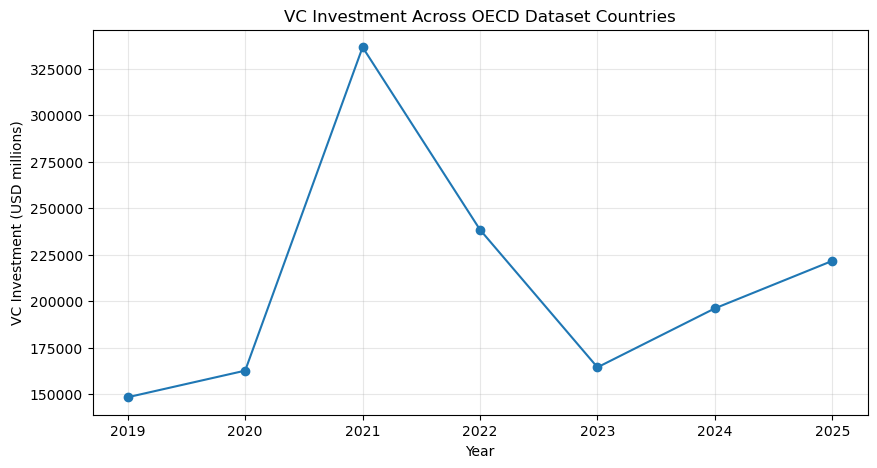

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    annual_vc["year"],
    annual_vc["vc_investment_usd_millions"],
    marker="o"
)

ax.set_title("VC Investment Across OECD Dataset Countries")
ax.set_xlabel("Year")
ax.set_ylabel("VC Investment (USD millions)")
ax.grid(alpha=0.3)

plt.show()

### Trend Interpretation

Reported VC investment across the countries in the dataset increased from approximately $148.3 billion in 2019 to a peak of $336.6 billion in 2021.

Investment subsequently declined to approximately $164.4 billion in 2023 before recovering to $196.1 billion in 2024 and $221.7 billion in 2025.

The recovery is therefore meaningful but incomplete: 2025 investment remains substantially below the 2021 peak. The data do not support describing the post-GPT period as a simple return to the previous VC market peak.

## 5. Geographic Distribution of Venture Capital

The following analysis ranks countries by cumulative reported VC investment over the 2019–2025 period.

Because venture capital markets differ substantially in scale, the objective is also to determine how geographically concentrated investment is within the OECD dataset.

In [27]:
country_totals = (
    total_vc
    .groupby(["country_code", "country"], as_index=False)
    ["vc_investment_usd_millions"]
    .sum()
    .sort_values(
        "vc_investment_usd_millions",
        ascending=False
    )
)

country_totals.head(15)

,country_code,country,vc_investment_usd_millions
35,USA,United States,"1,184,907.20"
18,ISR,Israel,"82,608.29"
4,CAN,Canada,"37,088.49"
13,GBR,United Kingdom,"33,842.65"
21,KOR,Korea,"21,450.03"
7,DEU,Germany,"21,328.57"
12,FRA,France,"17,615.94"
20,JPN,Japan,"14,299.59"
25,NLD,Netherlands,"8,072.47"
9,ESP,Spain,"7,627.17"


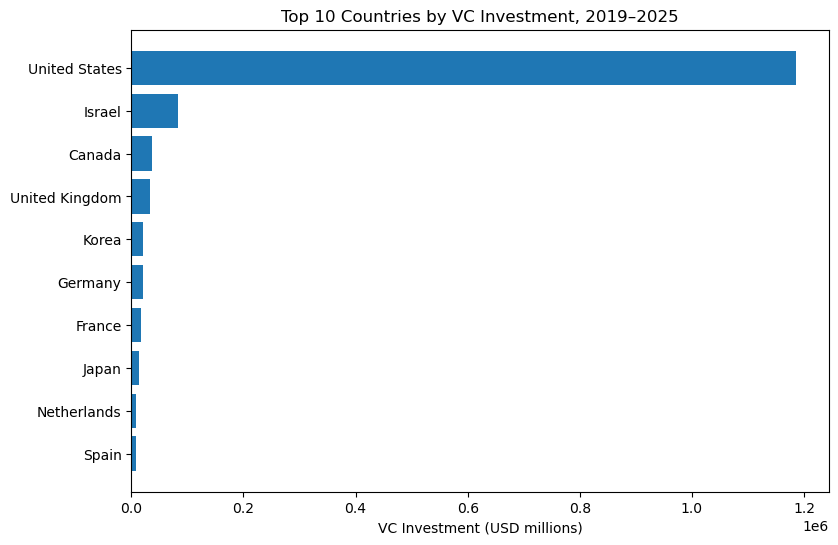

In [28]:
top_10 = country_totals.head(10).sort_values(
    "vc_investment_usd_millions"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_10["country"],
    top_10["vc_investment_usd_millions"]
)

ax.set_title("Top 10 Countries by VC Investment, 2019–2025")
ax.set_xlabel("VC Investment (USD millions)")

plt.show()

### Geographic Concentration

The United States dominates the dataset, with approximately $1.18 trillion of reported VC investment over 2019–2025. Israel, Canada, the United Kingdom, and Korea follow at substantially lower levels.

Consequently, aggregate OECD VC trends are strongly influenced by the largest national markets, particularly the United States. Country rankings should therefore be considered alongside concentration measures rather than interpreted as equally weighted national trends.

## 6. Investment by Business Development Stage

The OECD dataset distinguishes three component stages:

- Seed;
- Start-up and other early stage; and
- Later stage venture.

Stage analysis is restricted to country-year observations for which the relevant stage data are reported. The processed data contain all three component stages for 217 country-year observations, compared with 244 total-investment observations. The reported components reconcile with the corresponding total within rounding tolerance. Stage shares use the sum of reported stage investment as their denominator.

In [29]:
annual_stage = (
    stage_vc
    .groupby(["year", "stage"], as_index=False)
    ["vc_investment_usd_millions"]
    .sum()
)

annual_stage_pivot = annual_stage.pivot(
    index="year",
    columns="stage",
    values="vc_investment_usd_millions"
)

annual_stage_pivot

stage,Later stage venture,Seed,Start-up and other early stage
year,,,
2019,"73,246.02","11,862.64","57,298.15"
2020,"85,616.41","13,875.94","58,272.71"
2021,"193,902.92","22,446.94","112,221.24"
2022,"114,504.41","28,791.33","88,713.34"
2023,"86,742.88","19,976.78","52,882.13"
2024,"100,869.00","21,629.58","68,262.00"
2025,"113,199.61","24,560.76","80,863.42"


In [30]:
stage_share = annual_stage_pivot.div(
    annual_stage_pivot.sum(axis=1),
    axis=0
)

stage_share

stage,Later stage venture,Seed,Start-up and other early stage
year,,,
2019,0.51,0.08,0.40
2020,0.54,0.09,0.37
2021,0.59,0.07,0.34
2022,0.49,0.12,0.38
2023,0.54,0.13,0.33
2024,0.53,0.11,0.36
2025,0.52,0.11,0.37


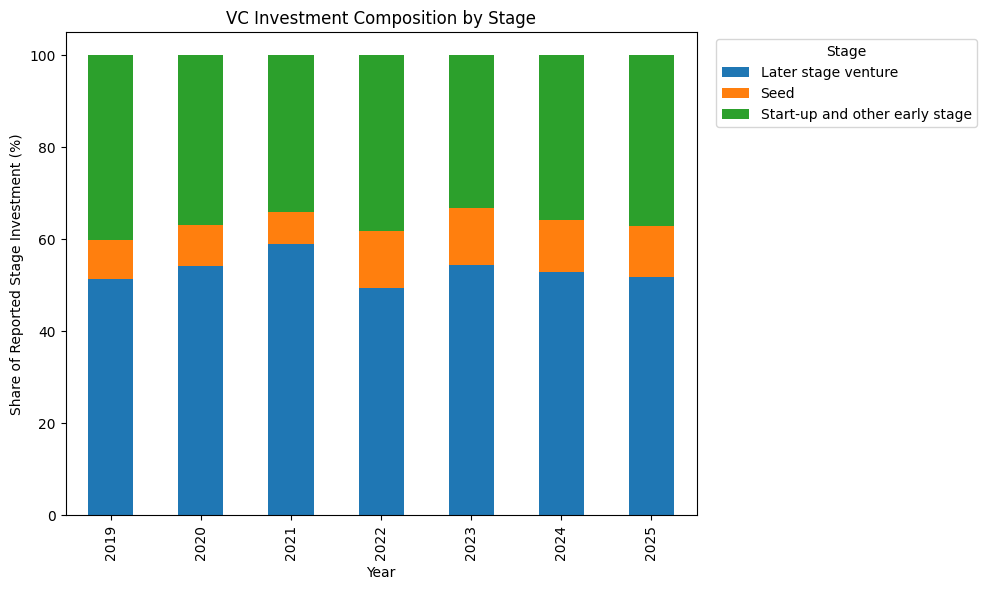

In [ ]:
stage_share_pct = stage_share * 100

fig, ax = plt.subplots(figsize=(10, 6))

stage_share_pct.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title("VC Investment Composition by Stage")
ax.set_xlabel("Year")
ax.set_ylabel("Share of Reported Stage Investment (%)")
ax.legend(title="Stage", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Stage Composition

Later-stage venture represents the largest share of reported investment in every year examined.

Its share peaked at approximately 59% in 2021 before declining to around 49% in 2022 and remaining close to 52–54% during 2023–2025.

Seed investment represents a comparatively small share of total stage-level funding, although its share is higher in the post-2022 observations than during most of the pre-GPT period.

These figures describe the stage composition of observations with complete stage reporting and should not be assumed to represent every country-year observation in the broader dataset.

## 7. Pre-GPT and Post-GPT Comparison

Because the OECD data are annual, the quarterly breakpoint defined in the broader project methodology cannot be applied directly.

For this dataset:

- **2019–2021** is classified as Pre-GPT;
- **2022** is treated as a transition year; and
- **2023–2025** is classified as Post-GPT.

The transition year is excluded from direct pre/post comparisons.

This classification is descriptive and does not imply that the release of ChatGPT caused subsequent changes in venture capital investment.

In [31]:
def classify_period(year):
    if year <= 2021:
        return "Pre-GPT"
    elif year == 2022:
        return "Transition"
    else:
        return "Post-GPT"


total_vc["market_period"] = total_vc["year"].apply(
    classify_period
)

In [32]:
period_summary = (
    total_vc[
        total_vc["market_period"] != "Transition"
    ]
    .groupby("market_period")
    ["vc_investment_usd_millions"]
    .agg(["sum", "mean", "median"])
)

period_summary

,sum,mean,median
market_period,,,
Post-GPT,"582,151.47","5,707.37",270.16
Pre-GPT,"647,501.14","6,051.41",242.75


The first comparison summarizes individual country-year observations. Its mean and median therefore describe the distribution of investment across country-year records rather than annual aggregate market investment.

For the headline temporal comparison, annual country totals are aggregated first and then compared across the pre-GPT and post-GPT periods.

In [33]:
annual_period_summary = (
    annual_vc
    .assign(
        market_period=lambda x: x["year"].map(
            {
                2019: "Pre-GPT",
                2020: "Pre-GPT",
                2021: "Pre-GPT",
                2022: "Transition",
                2023: "Post-GPT",
                2024: "Post-GPT",
                2025: "Post-GPT",
            }
        )
    )
    .query("market_period != 'Transition'")
    .groupby("market_period")[
        "vc_investment_usd_millions"
    ]
    .agg(["sum", "mean"])
)

annual_period_summary

,sum,mean
market_period,,
Post-GPT,"582,151.47","194,050.49"
Pre-GPT,"647,501.14","215,833.71"


### Pre/Post Comparison

Aggregate reported investment was approximately $647.5 billion during 2019–2021 and $582.2 billion during 2023–2025.

Because both periods contain three calendar years, average annual investment declined from approximately $215.8 billion in the pre-GPT period to $194.1 billion in the post-GPT period, a decrease of approximately 10.1%.

The OECD country-level data therefore do not indicate a broad increase in aggregate VC investment during the post-GPT period. This does not rule out substantial growth within particular sectors, especially AI, which will be investigated using dedicated AI investment data.

## 8. Geographic Funding Concentration

Aggregate investment can rise or fall independently of how widely capital is distributed geographically.

To measure concentration, the share of annual VC investment captured by the five largest countries is calculated for each year.

In [34]:
def top_n_share(group, n=5):
    values = group["vc_investment_usd_millions"]

    if values.sum() == 0:
        return 0

    return (
        values.nlargest(n).sum()
        / values.sum()
    )


top5_share = (
    total_vc
    .groupby("year")
    .apply(top_n_share, include_groups=False)
    .reset_index(name="top5_funding_share")
)

top5_share["top5_funding_share_pct"] = (
    top5_share["top5_funding_share"] * 100
)

top5_share

,year,top5_funding_share,top5_funding_share_pct
0,2019,0.92,91.82
1,2020,0.93,92.79
2,2021,0.94,93.79
3,2022,0.93,92.83
4,2023,0.92,91.83
5,2024,0.92,91.83
6,2025,0.94,93.97


### Concentration Interpretation

The five largest national VC markets account for approximately 92–94% of reported investment in every year examined.

Geographic concentration is therefore consistently high. However, the series does not show a clear increase in concentration across the entire post-GPT period. The highest observed value occurs in 2025, but pre-GPT years such as 2021 were similarly concentrated.

This distinction is important for the broader project: geographic concentration does not necessarily imply that company-level or AI-sector concentration followed the same pattern.

## 9. Key Findings and Limitations

### Key Findings

1. Reported VC investment increased sharply through 2021, contracted substantially through 2023, and partially recovered in 2024–2025.

2. The 2025 level remained below the 2021 investment peak, indicating that the recent recovery was incomplete within this dataset.

3. A balanced-panel robustness check produces the same broad temporal pattern, suggesting that changes in country coverage do not explain the main trend.

4. Venture capital investment is highly geographically concentrated, with the United States accounting for the majority of reported investment.

5. The five largest countries consistently account for more than 90% of annual reported VC investment.

6. Later-stage investment represents the largest component of reported stage-level VC funding, although seed funding accounts for a somewhat larger share in recent years.

7. Average annual aggregate investment during 2023–2025 remained below the corresponding 2019–2021 level.

### Limitations

- The OECD dataset does not represent the complete global venture capital market.
- Country coverage and national reporting methodologies are not perfectly uniform. Each comparison period contains three calendar years, but not every country reports in every year.
- Stage-level coverage is less complete than total-investment coverage; stage shares describe the available stage-reporting sample.
- Annual observations do not permit a precise November 2022 structural breakpoint.
- Values are reported in exchange-rate-converted US dollars; this notebook does not adjust for inflation or isolate exchange-rate effects.
- Pre/post comparisons are descriptive and should not be interpreted causally.
- The dataset does not identify AI, generative AI, individual companies, or individual funding rounds.

These limitations motivate the integration of additional market intelligence datasets in subsequent stages of the project.